In [1]:
# Install required packages
!pip install -q "git+https://github.com/AIM-Harvard/pyradiomics.git" SimpleITK pandas tqdm

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 8.5 MB/s eta 0:00:00
Mounted at /content/drive


In [ ]:
%%writefile patch_radiomics_extraction.py
from __future__ import annotations

import argparse
import hashlib
import itertools
import json
import logging
import os
import time
import warnings
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

import numpy as np
import pandas as pd
import SimpleITK as sitk
from radiomics import featureextractor

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(it, **kwargs):
        return it

# =============================================================================
# 1. CONFIGURATION
# =============================================================================

# Updated to point to our newly unified dataset
DATA_ROOT = "/content/drive/MyDrive/Combined_Glioma_Dataset"
METADATA_TSV_PATH = "/content/drive/MyDrive/Combined_Glioma_Dataset/combined_metadata.csv"
IMAGES_ROOT_DIR = DATA_ROOT

OUTPUT_DIR = "/content/drive/MyDrive/Combined_Glioma_Radiomics/patch_radiomics"
OUTPUT_CSV_NAME = "patch_radiomics_features.csv"

# Unified metadata column names
PATIENT_ID_COL = "standard_id"
LABEL_COL = "label"
UNKNOWN_LABEL = -1

LABEL_POSITIVE_VALUES = {"1", "1.0", "yes", "positive", "co-deleted", "codeleted"}
LABEL_NEGATIVE_VALUES = {"0", "0.0", "no", "negative", "intact", "non-codeleted"}

MODALITIES = ["T1", "T1CE", "T2", "FLAIR"]

# Since we standardized the dataset, we only need exactly one template per file
IMAGE_PATH_TEMPLATES = {
    "T1":    os.path.join("{root}", "{subject_id}", "T1.nii.gz"),
    "T1CE":  os.path.join("{root}", "{subject_id}", "T1CE.nii.gz"),
    "T2":    os.path.join("{root}", "{subject_id}", "T2.nii.gz"),
    "FLAIR": os.path.join("{root}", "{subject_id}", "FLAIR.nii.gz"),
}
SEG_PATH_TEMPLATE = os.path.join("{root}", "{subject_id}", "segmentation.nii.gz")

TUMOR_LABELS = None
TARGET_SPACING = (1.0, 1.0, 1.0)
IMAGE_INTERPOLATOR = "linear"
MASK_INTERPOLATOR = "nearest"
ALIGN_TO_MASK = True
GEOMETRY_TOLERANCE = 1e-3
NORMALIZATION = "zscore"
CLIP_PERCENTILES = None
PATCH_SIZE = (32, 32, 32)
PATCH_STRIDE = (16, 16, 16)
PATCH_OVERLAP = 0.5
BBOX_MARGIN_VOXELS = 0
MIN_TUMOR_FRACTION = 0.25
MIN_TUMOR_VOXELS = 500
MAX_PATCHES_PER_PATIENT = None

FEATURE_CLASSES = ["shape", "firstorder", "glcm", "glrlm", "glszm", "gldm", "ngtdm"]
IMAGE_TYPES = {"Original": {}}
BIN_WIDTH = 0.25
BIN_COUNT = None

RADIOMICS_SETTINGS = {
    "distances": [1],
    "force2D": False,
    "symmetricalGLCM": True,
    "voxelArrayShift": 0,
}

N_WORKERS = 2
RESUME = True
KEEP_PATCH_METADATA = True

# =============================================================================
# 2. IMPLEMENTATION
# =============================================================================

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s",
                    datefmt="%H:%M:%S")
logger = logging.getLogger("patch_radiomics")
logging.getLogger("radiomics").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=FutureWarning)

_INTERPOLATORS = {
    "nearest": sitk.sitkNearestNeighbor,
    "linear": sitk.sitkLinear,
    "bspline": sitk.sitkBSpline,
}

_FINGERPRINT_KEYS = [
    "MODALITIES", "TUMOR_LABELS", "TARGET_SPACING", "IMAGE_INTERPOLATOR", "MASK_INTERPOLATOR",
    "ALIGN_TO_MASK", "NORMALIZATION", "CLIP_PERCENTILES", "PATCH_SIZE", "PATCH_STRIDE",
    "PATCH_OVERLAP", "BBOX_MARGIN_VOXELS", "MIN_TUMOR_FRACTION", "MIN_TUMOR_VOXELS",
    "MAX_PATCHES_PER_PATIENT", "FEATURE_CLASSES", "IMAGE_TYPES", "BIN_WIDTH", "BIN_COUNT",
    "RADIOMICS_SETTINGS", "KEEP_PATCH_METADATA",
]

def _as_triplet(value, name):
    if isinstance(value, (int, np.integer)):
        return (int(value), int(value), int(value))
    value = tuple(int(v) for v in value)
    if len(value) != 3 or any(v < 1 for v in value):
        raise ValueError(f"{name} must be a positive int or 3 positive ints, got {value}")
    return value

def get_patch_size():
    return _as_triplet(PATCH_SIZE, "PATCH_SIZE")

def get_patch_stride():
    size = get_patch_size()
    if PATCH_STRIDE is not None:
        return _as_triplet(PATCH_STRIDE, "PATCH_STRIDE")
    if PATCH_OVERLAP is None or not (0 <= PATCH_OVERLAP < 1):
        raise ValueError("Set PATCH_STRIDE, or PATCH_OVERLAP in [0, 1).")
    return tuple(max(1, int(round(s * (1 - PATCH_OVERLAP)))) for s in size)

def config_fingerprint():
    cfg = {k: globals()[k] for k in _FINGERPRINT_KEYS}
    cfg["_resolved_patch_stride"] = get_patch_stride()
    blob = json.dumps(cfg, sort_keys=True, default=str)
    return hashlib.sha1(blob.encode()).hexdigest()[:12], cfg

def _config_snapshot():
    return {k: v for k, v in globals().items() if k.isupper() and not k.startswith("_")}

def _init_worker(cfg):
    globals().update(cfg)
    sitk.ProcessObject.SetGlobalDefaultNumberOfThreads(1)

def _normalise_label(raw):
    if raw is None or pd.isna(raw):
        return UNKNOWN_LABEL
    s = str(raw).strip().lower()
    if s in LABEL_POSITIVE_VALUES:
        return 1
    if s in LABEL_NEGATIVE_VALUES:
        return 0
    return UNKNOWN_LABEL

def load_label_map():
    if not METADATA_TSV_PATH or not os.path.isfile(METADATA_TSV_PATH):
        logger.warning("Metadata CSV not found (%s)", METADATA_TSV_PATH)
        return {}

    df = pd.read_csv(METADATA_TSV_PATH)
    label_map = {}
    for sid, raw in zip(df[PATIENT_ID_COL], df[LABEL_COL]):
        if pd.isna(sid):
            continue
        sid, lab = str(sid).strip(), _normalise_label(raw)
        if label_map.get(sid, UNKNOWN_LABEL) == UNKNOWN_LABEL:
            label_map[sid] = lab

    counts = pd.Series(list(label_map.values())).value_counts().to_dict()
    logger.info("Loaded labels for %d subjects: %s", len(label_map), counts)
    return label_map

def locate_files(subject_id):
    paths, missing = {}, []
    for mod in MODALITIES:
        p = IMAGE_PATH_TEMPLATES[mod].format(root=IMAGES_ROOT_DIR, subject_id=subject_id)
        (paths.__setitem__(mod, p) if os.path.isfile(p) else missing.append(mod))

    seg = SEG_PATH_TEMPLATE.format(root=IMAGES_ROOT_DIR, subject_id=subject_id)
    if os.path.isfile(seg):
        paths["segmentation"] = seg
    else:
        missing.append("segmentation")

    if missing:
        raise FileNotFoundError(f"missing: {', '.join(missing)}")
    return paths

def discover_subjects():
    root = Path(IMAGES_ROOT_DIR)
    if not root.is_dir():
        raise FileNotFoundError(f"DATA_ROOT does not exist: {root}")
    return sorted(p.name for p in root.iterdir() if p.is_dir() and not p.name.startswith("."))

def _same_geometry(a, b, tol=None):
    tol = GEOMETRY_TOLERANCE if tol is None else tol
    return (a.GetSize() == b.GetSize()
            and np.allclose(a.GetSpacing(), b.GetSpacing(), atol=tol)
            and np.allclose(a.GetOrigin(), b.GetOrigin(), atol=tol)
            and np.allclose(a.GetDirection(), b.GetDirection(), atol=tol))

def _resample(img, *, spacing=None, reference=None, interpolator="linear"):
    f = sitk.ResampleImageFilter()
    f.SetInterpolator(_INTERPOLATORS[interpolator])
    f.SetDefaultPixelValue(0)
    f.SetOutputPixelType(img.GetPixelID())
    if reference is not None:
        f.SetReferenceImage(reference)
    else:
        in_sp, in_sz = np.array(img.GetSpacing()), np.array(img.GetSize())
        out_sp = np.array(spacing, dtype=float)
        out_sz = np.maximum(np.round(in_sz * in_sp / out_sp), 1).astype(int)
        f.SetOutputSpacing(out_sp.tolist())
        f.SetSize([int(s) for s in out_sz])
        f.SetOutputOrigin(img.GetOrigin())
        f.SetOutputDirection(img.GetDirection())
    return f.Execute(img)

def _binary_tumor_mask(seg_img):
    arr = sitk.GetArrayFromImage(seg_img)
    binary = (arr > 0) if TUMOR_LABELS is None else np.isin(arr, list(TUMOR_LABELS))
    out = sitk.GetImageFromArray(binary.astype(np.uint8))
    out.CopyInformation(seg_img)
    return out

def _normalise_intensity(img):
    if NORMALIZATION == "none":
        return img
    if NORMALIZATION != "zscore":
        raise ValueError(f"Unknown NORMALIZATION '{NORMALIZATION}'")
    arr = sitk.GetArrayFromImage(img).astype(np.float32)
    fg = arr != 0
    if fg.sum() < 100:
        fg = np.ones_like(fg)
    if CLIP_PERCENTILES is not None:
        lo, hi = np.percentile(arr[fg], CLIP_PERCENTILES)
        arr = np.clip(arr, lo, hi)
    mean, std = float(arr[fg].mean()), float(arr[fg].std())
    if std < 1e-8:
        raise ValueError("image has no intensity variation inside the brain")
    arr[fg] = (arr[fg] - mean) / std
    arr[~fg] = 0
    out = sitk.GetImageFromArray(arr)
    out.CopyInformation(img)
    return out

def load_and_preprocess(paths, subject_id):
    seg = sitk.ReadImage(paths["segmentation"])
    mask = _binary_tumor_mask(seg)
    if sitk.GetArrayViewFromImage(mask).sum() == 0:
        raise ValueError("segmentation contains no tumour voxels")

    images = {}
    for mod in MODALITIES:
        img = sitk.ReadImage(paths[mod], sitk.sitkFloat32)
        if _same_geometry(img, mask):
            img.CopyInformation(mask)
        elif ALIGN_TO_MASK:
            logger.warning("%s: %s grid differs from the mask - resampling onto mask grid.", subject_id, mod)
            img = _resample(img, reference=mask, interpolator=IMAGE_INTERPOLATOR)
        else:
            raise ValueError(f"{mod} geometry does not match the segmentation")
        images[mod] = _normalise_intensity(img)

    if TARGET_SPACING is not None and not np.allclose(mask.GetSpacing(), TARGET_SPACING, atol=1e-3):
        mask = _resample(mask, spacing=TARGET_SPACING, interpolator=MASK_INTERPOLATOR)
        images = {m: _resample(i, spacing=TARGET_SPACING, interpolator=IMAGE_INTERPOLATOR)
                  for m, i in images.items()}
        if sitk.GetArrayViewFromImage(mask).sum() == 0:
            raise ValueError("tumour vanished after resampling (too small for TARGET_SPACING)")
    return mask, images

def _axis_starts(lo, hi, size, stride, dim):
    if dim < size:
        raise ValueError(f"volume axis ({dim} voxels) is smaller than the patch size ({size})")
    if hi - lo <= size:
        starts = [int(round((lo + hi) / 2 - size / 2))]
    else:
        starts = list(range(lo, hi - size + 1, stride))
        if starts[-1] + size < hi:
            starts.append(hi - size)
    return sorted({min(max(s, 0), dim - size) for s in starts})

def generate_tumor_patches(mask_img):
    size, stride = np.array(get_patch_size()), get_patch_stride()
    mask_xyz = np.ascontiguousarray(sitk.GetArrayFromImage(mask_img).transpose(2, 1, 0)).astype(bool)
    shape = np.array(mask_xyz.shape)

    idx = np.argwhere(mask_xyz)
    lo = np.maximum(idx.min(0) - BBOX_MARGIN_VOXELS, 0)
    hi = np.minimum(idx.max(0) + 1 + BBOX_MARGIN_VOXELS, shape)
    axes = [_axis_starts(int(lo[a]), int(hi[a]), int(size[a]), int(stride[a]), int(shape[a]))
            for a in range(3)]

    n_voxels = int(size.prod())
    kept, n_candidates = [], 0
    for start in itertools.product(*axes):
        n_candidates += 1
        window = mask_xyz[tuple(slice(s, s + int(z)) for s, z in zip(start, size))]
        n_tumor = int(np.count_nonzero(window))
        frac = n_tumor / n_voxels
        if n_tumor >= MIN_TUMOR_VOXELS and frac >= MIN_TUMOR_FRACTION - 1e-12:
            kept.append({"start": tuple(int(s) for s in start), "n_tumor": n_tumor, "fraction": frac})

    if MAX_PATCHES_PER_PATIENT is not None and len(kept) > MAX_PATCHES_PER_PATIENT:
        kept = sorted(kept, key=lambda p: -p["fraction"])[:MAX_PATCHES_PER_PATIENT]
        kept.sort(key=lambda p: p["start"])
    return kept, n_candidates, (lo.tolist(), hi.tolist())

def _crop(img, start, size):
    return sitk.RegionOfInterest(img, [int(s) for s in size], [int(s) for s in start])

def build_extractors():
    settings = dict(RADIOMICS_SETTINGS)
    settings.update(label=1, resampledPixelSpacing=None, normalize=False,
                    geometryTolerance=GEOMETRY_TOLERANCE, additionalInfo=False)
    if BIN_COUNT is not None:
        settings["binCount"] = int(BIN_COUNT)
    elif BIN_WIDTH is not None:
        settings["binWidth"] = float(BIN_WIDTH)
    else:
        raise ValueError("Set BIN_WIDTH or BIN_COUNT.")

    def make(classes, image_types):
        ext = featureextractor.RadiomicsFeatureExtractor(**settings)
        ext.disableAllFeatures()
        for c in classes:
            ext.enableFeatureClassByName(c)
        ext.disableAllImageTypes()
        for name, args in image_types.items():
            ext.enableImageTypeByName(name, customArgs=args or None)
        return ext

    texture = [c for c in FEATURE_CLASSES if c != "shape"]
    intensity_ext = make(texture, IMAGE_TYPES) if texture else None
    shape_ext = make(["shape"], {"Original": {}}) if "shape" in FEATURE_CLASSES else None
    return intensity_ext, shape_ext

def _run_extractor(extractor, image, mask):
    result = extractor.execute(image, mask, label=1)
    return {k: float(v) for k, v in result.items() if not k.startswith("diagnostics_")}

def _paths_for(subject_id):
    d = Path(OUTPUT_DIR) / "per_patient"
    return d / f"{subject_id}.csv", d / f"{subject_id}.status.json"

def process_patient(subject_id, label):
    t0 = time.time()
    fingerprint, _ = config_fingerprint()
    csv_path, status_path = _paths_for(subject_id)
    status = {PATIENT_ID_COL: subject_id, "status": "ok", "n_candidate_patches": 0,
              "n_retained_patches": 0, "n_failed_patches": 0, "n_rows": 0,
              "tumor_voxels": 0, "seconds": 0.0, "message": "", "fingerprint": fingerprint}
    csv_path.unlink(missing_ok=True)

    try:
        paths = locate_files(subject_id)
        mask, images = load_and_preprocess(paths, subject_id)
        status["tumor_voxels"] = int(sitk.GetArrayViewFromImage(mask).sum())

        patches, n_cand, (bb_lo, bb_hi) = generate_tumor_patches(mask)
        status["n_candidate_patches"], status["n_retained_patches"] = n_cand, len(patches)
        if not patches:
            status["status"] = "no_patches"
            status["message"] = (f"0/{n_cand} candidate patches passed "
                                 f"(tumour fraction>={MIN_TUMOR_FRACTION}, voxels>={MIN_TUMOR_VOXELS}); "
                                 f"tumour bbox {bb_lo}->{bb_hi}")
        else:
            intensity_ext, shape_ext = build_extractors()
            size = get_patch_size()
            rows = []
            for n, p in enumerate(patches, start=1):
                patch_id = f"Patch_{n:03d}"
                mask_patch = _crop(mask, p["start"], size)
                try:
                    shape_feats = (_run_extractor(shape_ext, _crop(images[MODALITIES[0]], p["start"], size),
                                                  mask_patch) if shape_ext else {})
                    mod_feats = {m: (_run_extractor(intensity_ext, _crop(images[m], p["start"], size), mask_patch)
                                     if intensity_ext else {}) for m in MODALITIES}
                except Exception as exc:
                    status["n_failed_patches"] += 1
                    logger.warning("%s %s: extraction failed (%s: %s) - patch dropped",
                                   subject_id, patch_id, type(exc).__name__, exc)
                    continue
                for m in MODALITIES:
                    row = {PATIENT_ID_COL: subject_id, "patch_id": patch_id, "modality": m}
                    if label is not None:
                        row["label"] = label
                    if KEEP_PATCH_METADATA:
                        row.update(tumor_fraction=round(p["fraction"], 6), n_tumor_voxels=p["n_tumor"],
                                   patch_x0=p["start"][0], patch_y0=p["start"][1], patch_z0=p["start"][2])
                    row.update(shape_feats)
                    row.update(mod_feats[m])
                    rows.append(row)
            if rows:
                pd.DataFrame(rows).to_csv(csv_path, index=False)
            else:
                status["status"] = "error"
                status["message"] = "all retained patches failed during feature extraction"
            status["n_rows"] = len(rows)
    except FileNotFoundError as exc:
        status.update(status="missing_files", message=str(exc))
    except Exception as exc:
        status.update(status="error", message=f"{type(exc).__name__}: {exc}")

    status["seconds"] = round(time.time() - t0, 1)
    csv_path.parent.mkdir(parents=True, exist_ok=True)
    status_path.write_text(json.dumps(status, indent=2))
    return status

def _is_done(subject_id, fingerprint):
    csv_path, status_path = _paths_for(subject_id)
    if not status_path.is_file():
        return False
    try:
        st = json.loads(status_path.read_text())
    except json.JSONDecodeError:
        return False
    if st.get("fingerprint") != fingerprint:
        return False
    return (st["status"] == "ok" and csv_path.is_file()) or st["status"] == "no_patches"

def maybe_mount_drive():
    if os.path.isdir(IMAGES_ROOT_DIR) or not str(IMAGES_ROOT_DIR).startswith("/content/drive"):
        return
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception as exc:
        logger.warning("Could not mount Google Drive automatically (%s). ", exc)

def merge_outputs(subjects):
    fingerprint, cfg = config_fingerprint()
    frames, summaries = [], []
    for sid in subjects:
        csv_path, status_path = _paths_for(sid)
        if not status_path.is_file():
            continue
        st = json.loads(status_path.read_text())
        if st.get("fingerprint") != fingerprint:
            continue
        summaries.append(st)
        if st["status"] == "ok" and csv_path.is_file():
            frames.append(pd.read_csv(csv_path, dtype={PATIENT_ID_COL: str, "patch_id": str, "modality": str}))

    out_dir = Path(OUTPUT_DIR)
    out_dir.mkdir(parents=True, exist_ok=True)
    if summaries:
        pd.DataFrame(summaries).drop(columns="fingerprint").to_csv(out_dir / "extraction_summary.csv", index=False)
    (out_dir / "run_config.json").write_text(json.dumps(cfg, indent=2, default=str))
    if not frames:
        logger.error("No features were extracted - see extraction_summary.csv for the reasons.")
        return None

    df = pd.concat(frames, ignore_index=True, sort=False)
    df["modality"] = pd.Categorical(df["modality"], categories=MODALITIES, ordered=True)
    df = df.sort_values([PATIENT_ID_COL, "patch_id", "modality"], kind="stable").reset_index(drop=True)
    df["modality"] = df["modality"].astype(str)
    out_csv = out_dir / OUTPUT_CSV_NAME
    df.to_csv(out_csv, index=False)
    return df, out_csv

def parse_args():
    ap = argparse.ArgumentParser(description="Patch-level radiomics extraction")
    ap.add_argument("--data-root", help="Override DATA_ROOT")
    ap.add_argument("--metadata", help="Override METADATA_TSV_PATH")
    ap.add_argument("--output-dir", help="Override OUTPUT_DIR")
    ap.add_argument("--patients", nargs="+", help="Only process these subject IDs")
    ap.add_argument("--max-patients", type=int, help="Only process the first N subjects")
    ap.add_argument("--workers", type=int, help="Override N_WORKERS")
    ap.add_argument("--no-resume", action="store_true", help="Re-process patients even if already done")
    args, _ = ap.parse_known_args()
    return args

def main():
    global DATA_ROOT, IMAGES_ROOT_DIR, METADATA_TSV_PATH, OUTPUT_DIR, N_WORKERS, RESUME
    args = parse_args()
    if args.data_root:
        DATA_ROOT = IMAGES_ROOT_DIR = args.data_root
    if args.metadata:
        METADATA_TSV_PATH = args.metadata
    if args.output_dir:
        OUTPUT_DIR = args.output_dir
    if args.workers:
        N_WORKERS = args.workers
    if args.no_resume:
        RESUME = False

    maybe_mount_drive()
    get_patch_size(), get_patch_stride()
    label_map = load_label_map()
    all_subjects = discover_subjects()

    # FILTERING: Exclude non-patient files (like combined_metadata.csv)
    filtered_subjects = []
    for s in all_subjects:
        if label_map.get(s, UNKNOWN_LABEL) == UNKNOWN_LABEL:
            continue
        seg_path = SEG_PATH_TEMPLATE.format(root=IMAGES_ROOT_DIR, subject_id=s)
        if not os.path.isfile(seg_path):
            continue
        filtered_subjects.append(s)

    logger.info("Found %d valid subjects kept after filtering for 1p19q codel and tumor mask presence.", len(filtered_subjects))
    subjects = filtered_subjects

    if args.patients:
        subjects = [s for s in subjects if s in set(args.patients)]
    if args.max_patients:
        subjects = subjects[: args.max_patients]
    if not subjects:
        raise SystemExit(f"No eligible subjects remain to process.")

    fingerprint, _ = config_fingerprint()
    todo = [s for s in subjects if not (RESUME and _is_done(s, fingerprint))]
    logger.info("%d subjects selected | %d to process | patch=%s stride=%s | min fraction=%.2f, min voxels=%d",
                len(subjects), len(todo), get_patch_size(), get_patch_stride(),
                MIN_TUMOR_FRACTION, MIN_TUMOR_VOXELS)
    (Path(OUTPUT_DIR) / "per_patient").mkdir(parents=True, exist_ok=True)

    def label_for(sid):
        return label_map.get(sid, UNKNOWN_LABEL) if label_map else None

    def report(st):
        msg = st["message"] and f" | {st['message']}"
        logger.info("%s: %s | %d/%d patches kept | %d rows | %.0fs%s", st[PATIENT_ID_COL], st["status"],
                    st["n_retained_patches"], st["n_candidate_patches"],
                    st["n_rows"], st["seconds"], msg)

    if todo:
        if N_WORKERS <= 1 or len(todo) == 1:
            for sid in tqdm(todo, desc="patients"):
                report(process_patient(sid, label_for(sid)))
        else:
            with ProcessPoolExecutor(max_workers=N_WORKERS, initializer=_init_worker,
                                     initargs=(_config_snapshot(),)) as pool:
                futures = [pool.submit(process_patient, sid, label_for(sid)) for sid in todo]
                for fut in tqdm(as_completed(futures), total=len(futures), desc="patients"):
                    report(fut.result())

    merged = merge_outputs(subjects)
    if merged is None:
        return
    df, out_csv = merged

    n_feat = len([c for c in df.columns if not c.startswith(("original_", "log-", "wavelet-", "square", "squareroot", "logarithm", "exponential", "gradient", "lbp"))])
    logger.info("Done: %d patients | %d patches | %d rows | %d feature columns", df[PATIENT_ID_COL].nunique(),
                df.groupby([PATIENT_ID_COL, "patch_id"]).ngroups, len(df), n_feat)
    logger.info("Final table : %s", out_csv)
    logger.info("Per-patient status : %s", Path(OUTPUT_DIR) / "extraction_summary.csv")

if __name__ == "__main__":
    main()

Writing patch_radiomics_extraction.py


In [ ]:
# Run over the entire cohort
!python patch_radiomics_extraction.py

# Alternatively, test on a single patient first:
# !python patch_radiomics_extraction.py --patients BT0001

12:47:57 | INFO | Loaded labels for 156 subjects: {0: 110, 1: 46}
12:47:57 | INFO | Found 156 valid subjects kept after filtering for 1p19q codel and tumor mask presence.
12:47:57 | INFO | 156 subjects selected | 156 to process | patch=(32, 32, 32) stride=(16, 16, 16) | min fraction=0.25, min voxels=500
patients:   0% 0/156 [00:00<?, ?it/s]12:48:31 | INFO | GLIOMA_001: ok | 36/60 patches kept | 144 rows | 34s
patients:   1% 1/156 [00:34<1:28:07, 34.11s/it]12:50:06 | INFO | GLIOMA_002: ok | 110/150 patches kept | 440 rows | 129s
patients:   1% 2/156 [02:09<2:59:47, 70.05s/it]12:50:41 | INFO | GLIOMA_004: ok | 35/36 patches kept | 140 rows | 34s
patients:   2% 3/156 [02:43<2:17:12, 53.81s/it]12:50:55 | INFO | GLIOMA_003: ok | 126/150 patches kept | 504 rows | 144s
patients:   3% 4/156 [02:58<1:36:59, 38.29s/it]12:51:32 | INFO | GLIOMA_005: ok | 51/60 patches kept | 204 rows | 51s
patients:   3% 5/156 [03:34<1:34:26, 37.53s/it]12:51:46 | INFO | GLIOMA_006: ok | 53/96 patches kept | 212 ro

In [2]:
!pip install -q kneed scikit-learn matplotlib pandas numpy

In [3]:
%%writefile cluster_habitats.py
import argparse
import logging
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from kneed import KneeLocator
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# =============================================================================
# CONFIGURATION
# =============================================================================
INPUT_CSV = "/content/drive/MyDrive/Combined_Glioma_Radiomics/patch_radiomics/patch_radiomics_features.csv"
OUTPUT_DIR = "/content/drive/MyDrive/Combined_Glioma_Outputs/patch_radiomics/habitats"
OUTPUT_CSV = "patch_habitats.csv"
ELBOW_PLOT = "elbow_curve.png"

# Dimensionality reduction: keep this percentage of variance (e.g., 0.95 = 95%)
PCA_VARIANCE = 0.95
MAX_K = 15
RANDOM_STATE = 42

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
logger = logging.getLogger("habitat_clustering")

def main():
    parser = argparse.ArgumentParser(description="Multi-parametric MRI Habitat Clustering")
    parser.add_argument("--input", type=str, default=INPUT_CSV, help="Path to extracted radiomics CSV")
    parser.add_argument("--outdir", type=str, default=OUTPUT_DIR, help="Directory to save outputs")
    args = parser.parse_args()

    input_path = Path(args.input)
    out_dir = Path(args.outdir)
    out_dir.mkdir(parents=True, exist_ok=True)

    if not input_path.is_file():
        raise FileNotFoundError(f"Input CSV not found at {input_path}")

    logger.info("Loading data from %s", input_path)
    df = pd.read_csv(input_path)

    # 1. IDENTIFY COLUMNS
    # All columns that aren't the patient/patch ID or modality are considered features
    meta_cols = ["standard_id", "patch_id", "label", "tumor_fraction", "n_tumor_voxels",
                 "patch_x0", "patch_y0", "patch_z0"]
    meta_cols = [c for c in meta_cols if c in df.columns]
    feat_cols = [c for c in df.columns if c not in meta_cols and c != "modality"]

    # 2. PIVOT THE DATA (Combine modalities per patch)
    logger.info("Pivoting modalities into a single row per patch...")
    # This creates a multi-index column structure: (Feature, Modality)
    df_pivot = df.pivot(index=meta_cols, columns="modality", values=feat_cols)

    # Flatten the columns to format: "T1CE_original_glcm_Contrast"
    df_pivot.columns = [f"{mod}_{feat}" for feat, mod in df_pivot.columns]
    df_pivot = df_pivot.reset_index()

    # Drop patches that failed on one or more modalities (contain NaNs)
    initial_rows = len(df_pivot)
    df_pivot = df_pivot.dropna()
    if len(df_pivot) < initial_rows:
        logger.warning("Dropped %d patches due to missing modality data.", initial_rows - len(df_pivot))

    logger.info("Final dataset: %d patches, %d multi-parametric features", len(df_pivot), len(df_pivot.columns) - len(meta_cols))

    # Extract feature matrix
    feature_names = [c for c in df_pivot.columns if c not in meta_cols]
    X_raw = df_pivot[feature_names].values

    # 3. SCALE FEATURES
    logger.info("Applying StandardScaler (Z-scoring features)...")
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_raw)

    # 4. DIMENSIONALITY REDUCTION (PCA)
    logger.info("Applying PCA to retain %d%% of variance...", int(PCA_VARIANCE * 100))
    pca = PCA(n_components=PCA_VARIANCE, random_state=RANDOM_STATE)
    X_pca = pca.fit_transform(X_scaled)
    logger.info("Reduced from %d to %d principal components.", X_raw.shape[1], X_pca.shape[1])

    # 5. FIND OPTIMAL K (Elbow Method)
    logger.info("Testing K from 2 to %d...", MAX_K)
    inertias = []
    K_range = range(2, MAX_K + 1)

    for k in K_range:
        kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
        kmeans.fit(X_pca)
        inertias.append(kmeans.inertia_)

    # Mathematically find the elbow
    knee = KneeLocator(list(K_range), inertias, curve="convex", direction="decreasing")
    optimal_k = knee.elbow

    if optimal_k is None:
        logger.warning("KneeLocator could not find a clear elbow. Defaulting to K=3.")
        optimal_k = 3
    else:
        logger.info("Optimal number of habitats (K) found: %d", optimal_k)

    # Plot and save the elbow curve for visual verification
    plt.figure(figsize=(8, 5))
    plt.plot(K_range, inertias, marker='o', linestyle='-', color='b')
    plt.axvline(x=optimal_k, color='r', linestyle='--', label=f'Optimal K = {optimal_k}')
    plt.title('Elbow Method For Optimal K')
    plt.xlabel('Number of Clusters (K)')
    plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
    plt.legend()
    plt.grid(True)
    plot_path = out_dir / ELBOW_PLOT
    plt.savefig(plot_path)
    plt.close()
    logger.info("Saved Elbow curve plot to %s", plot_path)

    # 6. FINAL CLUSTERING
    logger.info("Clustering all patches into %d habitats...", optimal_k)
    final_kmeans = KMeans(n_clusters=optimal_k, random_state=RANDOM_STATE, n_init=10)
    clusters = final_kmeans.fit_predict(X_pca)

    # 7. SAVE OUTPUT
    df_pivot["habitat"] = clusters

    # Reorder columns so habitat is right after the metadata
    cols = meta_cols + ["habitat"] + feature_names
    df_pivot = df_pivot[cols]

    out_csv = out_dir / OUTPUT_CSV
    df_pivot.to_csv(out_csv, index=False)
    logger.info("Successfully saved habitat map to %s", out_csv)

    # Quick summary of the discovered habitats
    counts = df_pivot["habitat"].value_counts().sort_index()
    logger.info("Habitat distribution across entire cohort:")
    for cluster_id, count in counts.items():
        logger.info("  Habitat %d: %d patches (%.1f%%)", cluster_id, count, (count/len(df_pivot))*100)

if __name__ == "__main__":
    main()

Writing cluster_habitats.py


In [4]:
!python cluster_habitats.py

2026-10-12 14:47:10,710 | INFO | Loading data from /content/drive/MyDrive/Combined_Glioma_Radiomics/patch_radiomics/patch_radiomics_features.csv
2026-10-12 14:47:14,889 | INFO | Pivoting modalities into a single row per patch...
2026-10-12 14:47:15,295 | INFO | Final dataset: 5105 patches, 428 multi-parametric features
2026-10-12 14:47:15,315 | INFO | Applying StandardScaler (Z-scoring features)...
2026-10-12 14:47:15,435 | INFO | Applying PCA to retain 95% of variance...
2026-10-12 14:47:16,265 | INFO | Reduced from 428 to 47 principal components.
2026-10-12 14:47:16,265 | INFO | Testing K from 2 to 15...
2026-10-12 14:47:43,112 | INFO | Optimal number of habitats (K) found: 7
2026-10-12 14:47:44,184 | INFO | Saved Elbow curve plot to /content/drive/MyDrive/Combined_Glioma_Outputs/patch_radiomics/habitats/elbow_curve.png
2026-10-12 14:47:44,184 | INFO | Clustering all patches into 7 habitats...
2026-10-12 14:48:01,846 | INFO | Successfully saved habitat map to /content/drive/MyDrive/C

Loading data...

--- Dataset Overview ---
Total Patches: 5105
Total Patients: 150
Total Features (excluding metadata): 428

Discovered Habitats: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


/tmp/ipykernel_4184/607954602.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='habitat', palette='viridis', ax=axes[0])


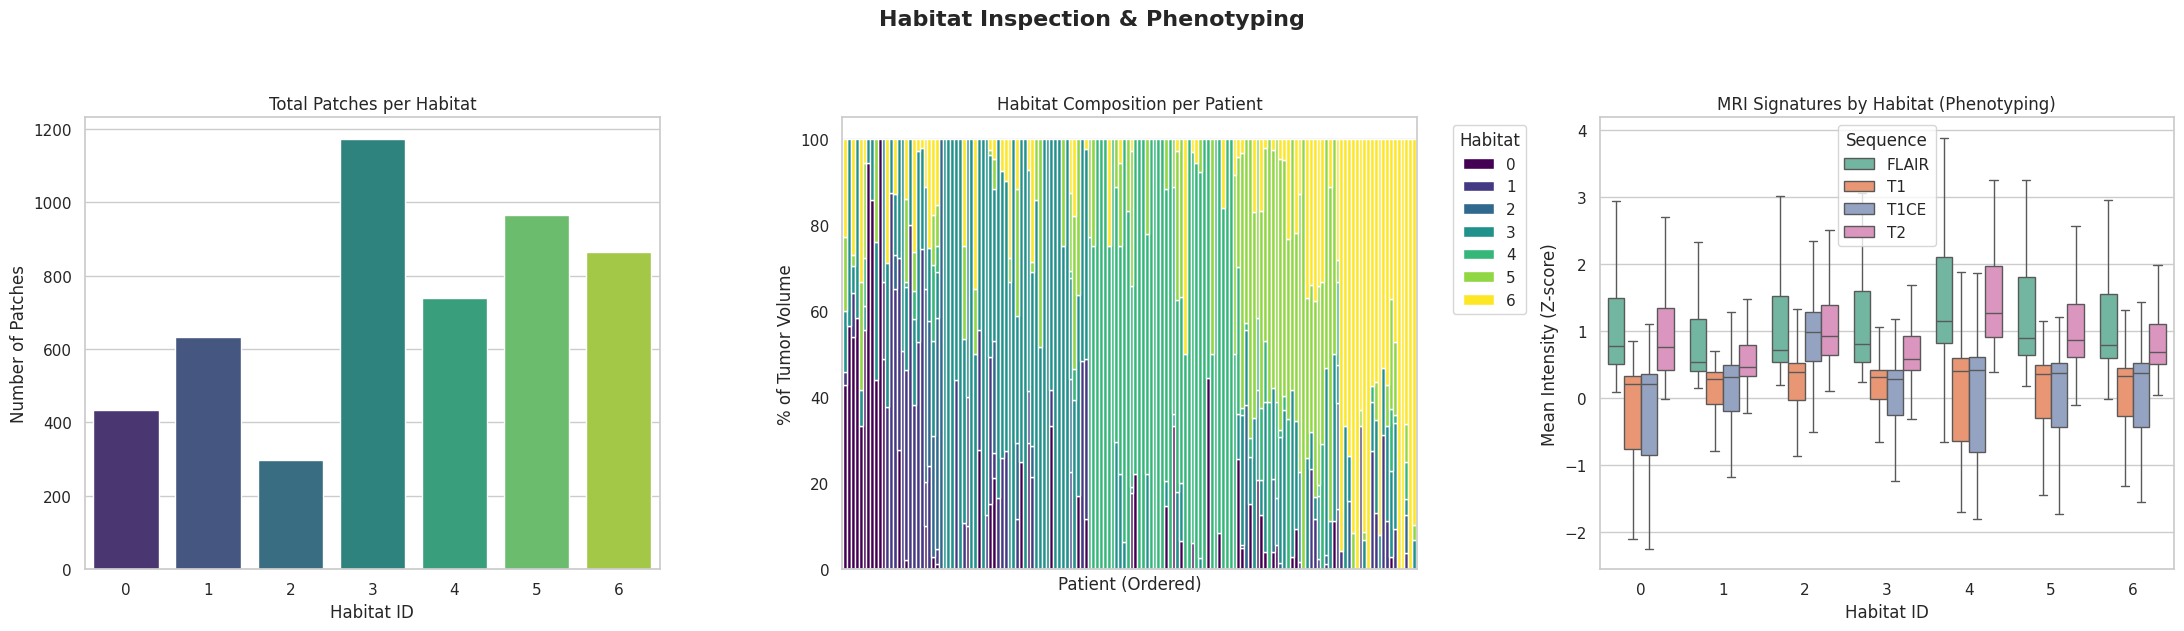


--- How to Interpret the Signatures Plot (Plot 3) ---
Look at the median lines in the boxplots to define what each habitat represents biologically:
  * High T1CE + Low T1  -> Likely Active Tumor (Enhancing)
  * High FLAIR + High T2 -> Likely Peritumoral Edema / Non-Enhancing Tumor
  * Low T1CE + Low T1   -> Likely Necrotic Core (Dead tissue)


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from pathlib import Path

# --- Configuration ---
HABITAT_CSV = "/content/drive/MyDrive/Combined_Glioma_Outputs/patch_radiomics/habitats/patch_habitats.csv"

# Set visualization style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (15, 5)

def inspect_habitats():
    csv_path = Path(HABITAT_CSV)
    if not csv_path.is_file():
        print(f"Error: Could not find {csv_path}. Did the clustering script finish successfully?")
        return

    print("Loading data...")
    df = pd.read_csv(csv_path)

    # 1. Basic Overview
    print("\n--- Dataset Overview ---")
    print(f"Total Patches: {len(df)}")
    print(f"Total Patients: {df['standard_id'].nunique()}")
    print(f"Total Features (excluding metadata): {len(df.columns) - 9}") # metadata + habitat col

    habitats = sorted(df['habitat'].unique())
    print(f"\nDiscovered Habitats: {habitats}")

    # Create a 1x3 subplot layout
    fig, axes = plt.subplots(1, 3, figsize=(22, 6))
    fig.suptitle("Habitat Inspection & Phenotyping", fontsize=16, fontweight='bold', y=1.05)

    # --- Plot 1: Overall Cohort Distribution ---
    sns.countplot(data=df, x='habitat', palette='viridis', ax=axes[0])
    axes[0].set_title("Total Patches per Habitat")
    axes[0].set_xlabel("Habitat ID")
    axes[0].set_ylabel("Number of Patches")

    # --- Plot 2: Patient-Level Heterogeneity ---
    # Calculate proportion of each habitat per patient
    patient_comp = df.groupby(['standard_id', 'habitat']).size().unstack(fill_value=0)
    patient_comp_pct = patient_comp.div(patient_comp.sum(axis=1), axis=0) * 100

    # Sort patients by their dominant habitat for a cleaner plot
    dominant_habitat = patient_comp_pct.idxmax(axis=1)
    patient_comp_pct = patient_comp_pct.loc[dominant_habitat.sort_values().index]

    patient_comp_pct.plot(kind='bar', stacked=True, colormap='viridis', width=1.0, ax=axes[1])
    axes[1].set_title("Habitat Composition per Patient")
    axes[1].set_xlabel("Patient (Ordered)")
    axes[1].set_ylabel("% of Tumor Volume")
    axes[1].set_xticks([]) # Hide x-ticks if there are too many patients
    axes[1].legend(title="Habitat", bbox_to_anchor=(1.05, 1), loc='upper left')

    # --- Plot 3: Biological Phenotyping (Mean Intensities) ---
    # Look for PyRadiomics mean intensity features
    mean_cols = [c for c in df.columns if "original_firstorder_Mean" in c]

    if mean_cols:
        # Melt the dataframe just for these specific columns so seaborn can plot them side-by-side
        df_melted = df.melt(id_vars=['habitat'], value_vars=mean_cols,
                            var_name='Modality', value_name='Mean Intensity (Z-score)')

        # Clean up the modality names for the legend (e.g., "T1CE_original_firstorder_Mean" -> "T1CE")
        df_melted['Modality'] = df_melted['Modality'].apply(lambda x: x.split('_')[0])

        sns.boxplot(data=df_melted, x='habitat', y='Mean Intensity (Z-score)',
                    hue='Modality', ax=axes[2], palette='Set2', showfliers=False)
        axes[2].set_title("MRI Signatures by Habitat (Phenotyping)")
        axes[2].set_xlabel("Habitat ID")
        axes[2].legend(title="Sequence")
    else:
        axes[2].text(0.5, 0.5, "Firstorder Mean features not found.\nCannot plot MRI signatures.",
                     ha='center', va='center')
        axes[2].set_title("MRI Signatures")

    plt.tight_layout()
    plt.show()

    # Print biological interpretation guide
    print("\n--- How to Interpret the Signatures Plot (Plot 3) ---")
    print("Look at the median lines in the boxplots to define what each habitat represents biologically:")
    print("  * High T1CE + Low T1  -> Likely Active Tumor (Enhancing)")
    print("  * High FLAIR + High T2 -> Likely Peritumoral Edema / Non-Enhancing Tumor")
    print("  * Low T1CE + Low T1   -> Likely Necrotic Core (Dead tissue)")

if __name__ == "__main__":
    inspect_habitats()

Analyzing 150 patients with known 1p/19q status...

--- Statistical Results (Mann-Whitney U Test) ---
Habitat 0: p-value = 0.5344 ns | Higher in: Neutral
Habitat 1: p-value = 0.0002 *** | Higher in: Neutral
Habitat 2: p-value = 0.5611 ns | Higher in: Neutral
Habitat 3: p-value = 0.0992 ns | Higher in: Co-deleted
Habitat 4: p-value = 0.6170 ns | Higher in: Co-deleted
Habitat 5: p-value = 0.0001 *** | Higher in: Co-deleted
Habitat 6: p-value = 0.0053 ** | Higher in: Intact


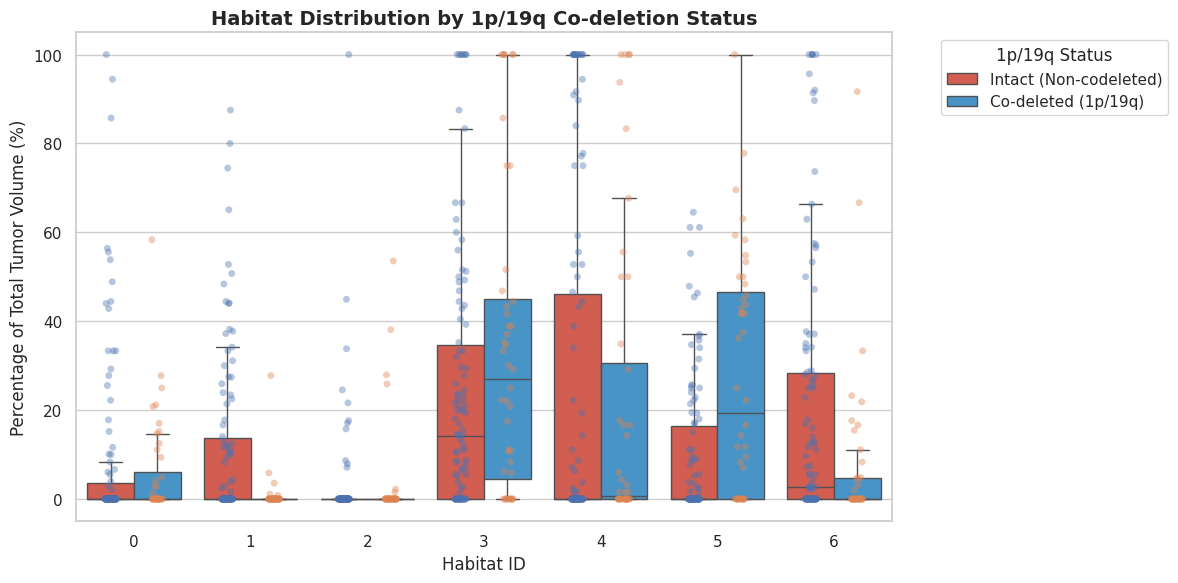

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu
from pathlib import Path

# --- Configuration ---
HABITAT_CSV = "/content/drive/MyDrive/Combined_Glioma_Outputs/patch_radiomics/habitats/patch_habitats.csv"

# Set visualization style
sns.set_theme(style="whitegrid")

def analyze_genomic_correlation():
    csv_path = Path(HABITAT_CSV)
    if not csv_path.is_file():
        print(f"Error: Could not find {csv_path}.")
        return

    df = pd.read_csv(csv_path)

    # 1. Filter out patients with unknown labels (-1)
    df_known = df[df['label'].isin([0, 1])].copy()

    if df_known.empty:
        print("Error: No patches found with a valid 1p/19q label (0 or 1). Check your metadata mapping.")
        return

    n_patients = df_known['standard_id'].nunique()
    print(f"Analyzing {n_patients} patients with known 1p/19q status...")

    # 2. Calculate patient-level habitat fractions (percentages)
    # Pivot table ensures that if a patient has 0 patches of Habitat X, it correctly records as 0%
    patient_counts = df_known.pivot_table(
        index=['standard_id', 'label'],
        columns='habitat',
        aggfunc='size',
        fill_value=0
    )

    # Convert raw counts to percentages of the total tumor volume
    patient_fractions = patient_counts.div(patient_counts.sum(axis=1), axis=0) * 100
    patient_fractions = patient_fractions.reset_index()

    # Map numeric labels to readable text for plots
    patient_fractions['Genomic Status'] = patient_fractions['label'].map({
        1: 'Co-deleted (1p/19q)',
        0: 'Intact (Non-codeleted)'
    })

    # 3. Statistical Testing (Mann-Whitney U)
    habitats = [col for col in patient_fractions.columns if isinstance(col, (int, np.integer))]

    print("\n--- Statistical Results (Mann-Whitney U Test) ---")
    results = []
    for hab in habitats:
        codel_vols = patient_fractions[patient_fractions['label'] == 1][hab]
        intact_vols = patient_fractions[patient_fractions['label'] == 0][hab]

        # Only run test if both groups have data
        if len(codel_vols) > 0 and len(intact_vols) > 0:
            stat, p_val = mannwhitneyu(codel_vols, intact_vols, alternative='two-sided')

            # Determine which group has a higher median expression of this habitat
            codel_med = codel_vols.median()
            intact_med = intact_vols.median()
            enriched_in = "Co-deleted" if codel_med > intact_med else "Intact"
            if codel_med == intact_med:
                enriched_in = "Neutral"

            sig_marker = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"

            print(f"Habitat {hab}: p-value = {p_val:.4f} {sig_marker} | Higher in: {enriched_in}")

            results.append({
                'Habitat': hab,
                'p_value': p_val,
                'Significance': sig_marker
            })

    # 4. Visualization: Boxplots of Habitat Fractions by Genomic Status
    # Melt dataframe for seaborn
    melted = patient_fractions.melt(
        id_vars=['standard_id', 'Genomic Status'],
        value_vars=habitats,
        var_name='Habitat',
        value_name='Tumor Volume (%)'
    )

    plt.figure(figsize=(12, 6))
    ax = sns.boxplot(
        data=melted,
        x='Habitat',
        y='Tumor Volume (%)',
        hue='Genomic Status',
        palette=['#e74c3c', '#3498db'],
        showfliers=False
    )

    # Overlay individual patient data points for transparency
    sns.stripplot(
        data=melted,
        x='Habitat',
        y='Tumor Volume (%)',
        hue='Genomic Status',
        dodge=True,
        alpha=0.4,
        ax=ax,
        legend=False
    )

    plt.title("Habitat Distribution by 1p/19q Co-deletion Status", fontsize=14, fontweight='bold')
    plt.xlabel("Habitat ID")
    plt.ylabel("Percentage of Total Tumor Volume (%)")
    plt.legend(title="1p/19q Status", bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    analyze_genomic_correlation()

--- Phenotyping Habitats based on MRI Intensities ---

Analyzing Habitat 0...
Defining Signature for Habitat 0:
  - T1CE: Hypointense (Dark) (Diff: -0.45, p=0.0000 *)
  - T1: Hypointense (Dark) (Diff: -0.42, p=0.0000 *)
  - T1CE: Hypointense (Dark) (Diff: -0.17, p=0.0000 *)
  - T2: Hyperintense (Bright) (Diff: 0.14, p=0.0000 *)
  - FLAIR: Hypointense (Dark) (Diff: -0.13, p=0.0003 *)
  - T1: Hypointense (Dark) (Diff: -0.12, p=0.0000 *)
  - T2: Hypointense (Dark) (Diff: -0.11, p=0.0000 *)
  - FLAIR: Hypointense (Dark) (Diff: -0.05, p=0.0000 *)

Analyzing Habitat 1...
Defining Signature for Habitat 1:
  - T2: Hypointense (Dark) (Diff: -0.55, p=0.0000 *)
  - FLAIR: Hypointense (Dark) (Diff: -0.46, p=0.0000 *)
  - T2: Hypointense (Dark) (Diff: -0.25, p=0.0000 *)
  - FLAIR: Hypointense (Dark) (Diff: -0.24, p=0.0000 *)
  - T1: Hyperintense (Bright) (Diff: 0.17, p=0.0000 *)
  - T1CE: Hyperintense (Bright) (Diff: 0.15, p=0.0000 *)
  - T1: Hypointense (Dark) (Diff: -0.07, p=0.0000 *)
  - T1CE: H

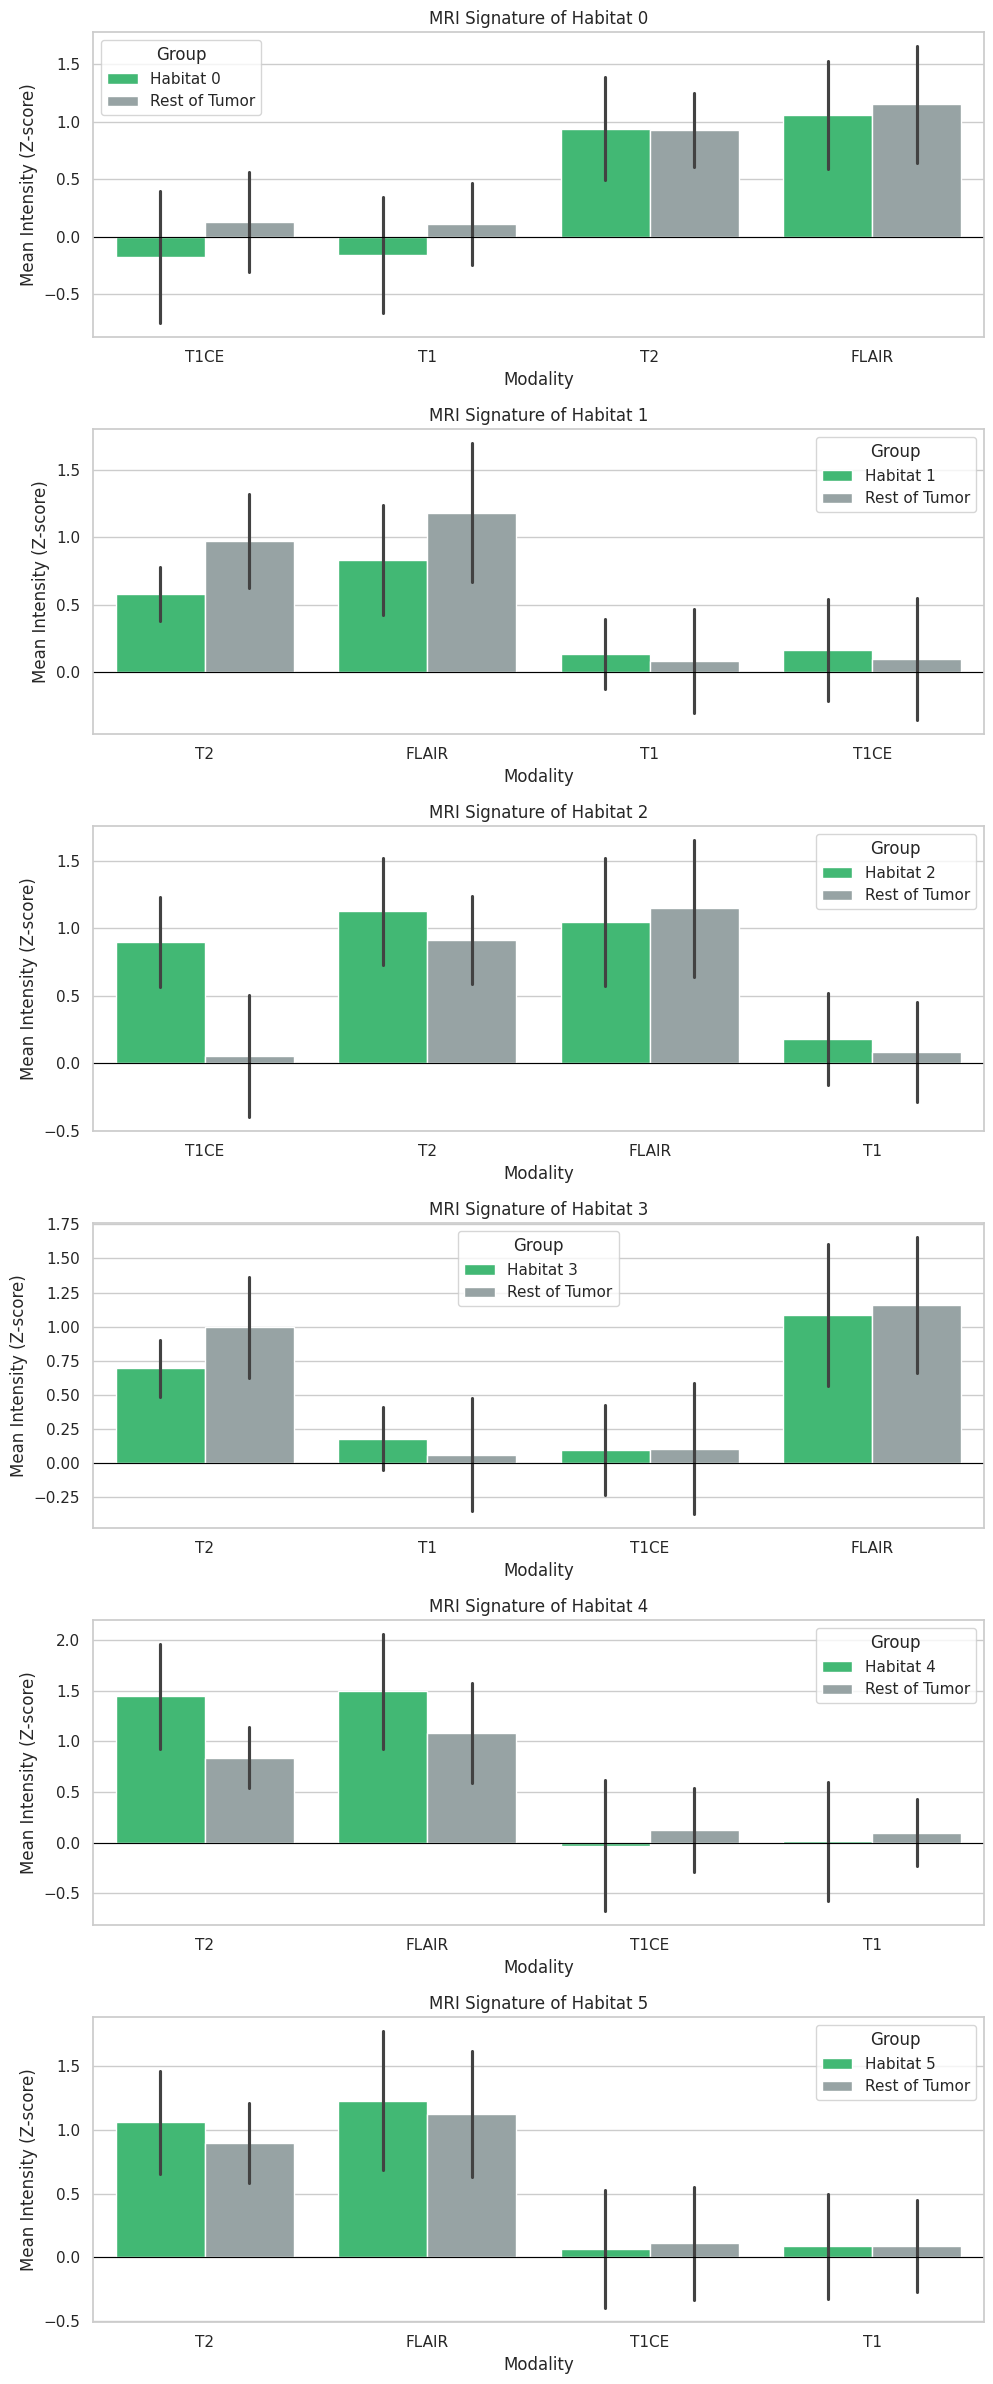

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import ttest_ind

# --- Configuration ---
HABITAT_CSV = "/content/drive/MyDrive/Combined_Glioma_Outputs/patch_radiomics/habitats/patch_habitats.csv"
TARGET_HABITATS = [0, 1, 2, 3, 4, 5] # The habitats you found significant

sns.set_theme(style="whitegrid")

def phenotype_habitats():
    csv_path = Path(HABITAT_CSV)
    if not csv_path.is_file():
        print(f"Error: Could not find {csv_path}.")
        return

    df = pd.read_csv(csv_path)

    # We want to look at the raw intensities first, as they are easiest to interpret
    # Find columns that represent the Mean intensity for each modality
    mean_intensity_cols = [c for c in df.columns if "original_firstorder_Mean" in c]

    if not mean_intensity_cols:
        print("Error: Could not find 'original_firstorder_Mean' features. Did you extract them?")
        return

    print("--- Phenotyping Habitats based on MRI Intensities ---")

    fig, axes = plt.subplots(len(TARGET_HABITATS), 1, figsize=(10, 4 * len(TARGET_HABITATS)))
    if len(TARGET_HABITATS) == 1:
        axes = [axes] # Make it iterable if only 1 target

    for i, target_hab in enumerate(TARGET_HABITATS):
        print(f"\nAnalyzing Habitat {target_hab}...")

        # Split patches into "This Habitat" vs "Rest of Tumor"
        in_hab = df[df['habitat'] == target_hab]
        out_hab = df[df['habitat'] != target_hab]

        if in_hab.empty:
            print(f"Skipping Habitat {target_hab} (no patches found).")
            continue

        results = []
        for col in mean_intensity_cols:
            modality = col.split('_')[0]

            val_in = in_hab[col].values
            val_out = out_hab[col].values

            # Perform a t-test to see if the intensity is significantly different
            stat, pval = ttest_ind(val_in, val_out, equal_var=False)

            mean_diff = np.mean(val_in) - np.mean(val_out)
            direction = "Hyperintense (Bright)" if mean_diff > 0 else "Hypointense (Dark)"

            results.append({
                'Modality': modality,
                'Mean_In': np.mean(val_in),
                'Mean_Out': np.mean(val_out),
                'Difference': mean_diff,
                'Direction': direction,
                'p_value': pval
            })

        res_df = pd.DataFrame(results).sort_values(by='Difference', key=abs, ascending=False)

        print(f"Defining Signature for Habitat {target_hab}:")
        for _, row in res_df.iterrows():
            sig = "*" if row['p_value'] < 0.05 else "ns"
            print(f"  - {row['Modality']}: {row['Direction']} (Diff: {row['Difference']:.2f}, p={row['p_value']:.4f} {sig})")

        # --- Plotting ---
        # Prepare data for a clean grouped bar chart
        plot_data = pd.DataFrame({
            'Modality': res_df['Modality'].tolist() * 2,
            'Intensity (Z-score)': res_df['Mean_In'].tolist() + res_df['Mean_Out'].tolist(),
            'Group': [f'Habitat {target_hab}'] * len(res_df) + ['Rest of Tumor'] * len(res_df)
        })

        sns.barplot(
            data=plot_data,
            x='Modality',
            y='Intensity (Z-score)',
            hue='Group',
            palette=['#2ecc71', '#95a5a6'],
            ax=axes[i]
        )
        axes[i].set_title(f"MRI Signature of Habitat {target_hab}")
        axes[i].set_ylabel("Mean Intensity (Z-score)")
        axes[i].axhline(0, color='black', linewidth=0.8) # Add a line at 0 (the brain average)

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    phenotype_habitats()

In [8]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.neighbors import NearestNeighbors
from scipy.stats import entropy

# --- Configuration ---
HABITAT_CSV = "/content/drive/MyDrive/Combined_Glioma_Outputs/patch_radiomics/habitats/patch_habitats.csv"
OUTPUT_SPATIAL_CSV = "/content/drive/MyDrive/Combined_Glioma_Outputs/patch_radiomics/habitats/spatial_architectures.csv"

# Number of physical neighbors to check for spatial mixing (6 is standard for a 3D grid)
N_NEIGHBORS = 6

def calculate_spatial_metrics():
    csv_path = Path(HABITAT_CSV)
    if not csv_path.is_file():
        print(f"Error: Could not find {csv_path}.")
        return

    print("Loading habitat data and computing spatial architectures...")
    df = pd.read_csv(csv_path)

    # Ensure coordinate columns exist
    coord_cols = ['patch_x0', 'patch_y0', 'patch_z0']
    if not all(c in df.columns for c in coord_cols):
        print(f"Error: Missing coordinate columns. Make sure {coord_cols} are in your CSV.")
        return

    results = []
    habitats_to_test = sorted(df['habitat'].unique())

    for standard_id, grp in df.groupby('standard_id'):
        coords = grp[coord_cols].values
        habitats = grp['habitat'].values
        label = grp['label'].iloc[0] if 'label' in grp.columns else -1

        n_patches = len(coords)
        if n_patches < N_NEIGHBORS + 1:
            continue

        # Geometric centroid of the tumor
        centroid = coords.mean(axis=0)
        dists_to_center = np.linalg.norm(coords - centroid, axis=1)

        # Define 'Core' as inner 50% and 'Edge' as outer 50% of patches
        median_dist = np.median(dists_to_center)
        is_core = dists_to_center <= median_dist
        is_edge = dists_to_center > median_dist

        # Global Shannon Entropy & Spatial Mixing Index (SMI)
        _, counts = np.unique(habitats, return_counts=True)
        shannon_ent = entropy(counts, base=2)

        nn = NearestNeighbors(n_neighbors=N_NEIGHBORS + 1).fit(coords)
        _, neighbor_indices = nn.kneighbors(coords)
        neighbor_indices = neighbor_indices[:, 1:]
        neighbor_habitats = habitats[neighbor_indices]
        center_habitats = habitats[:, np.newaxis]
        spatial_mixing_index = (neighbor_habitats != center_habitats).mean()

        # Initialize row data with general patient info
        row_data = {
            'standard_id': standard_id,
            'label': label,
            'Total_Patches': n_patches,
            'Global_Shannon_Entropy': round(shannon_ent, 3),
            'Spatial_Mixing_Index': round(spatial_mixing_index, 3)
        }

        # Calculate core/edge localization for each habitat dynamically
        for target_hab in habitats_to_test:
            hab_in_core = np.sum(habitats[is_core] == target_hab)
            hab_in_edge = np.sum(habitats[is_edge] == target_hab)

            core_fraction = hab_in_core / max(1, np.sum(is_core))
            edge_fraction = hab_in_edge / max(1, np.sum(is_edge))
            localization_index = (edge_fraction + 1e-5) / (core_fraction + 1e-5)

            row_data[f'Hab{target_hab}_Core_Volume_Pct'] = round(core_fraction * 100, 2)
            row_data[f'Hab{target_hab}_Edge_Volume_Pct'] = round(edge_fraction * 100, 2)
            row_data[f'Hab{target_hab}_Localization_Ratio'] = round(localization_index, 3)

        results.append(row_data)

    # Save to CSV
    res_df = pd.DataFrame(results)
    res_df.to_csv(OUTPUT_SPATIAL_CSV, index=False)
    print(f"\nSuccessfully processed {len(res_df)} patients.")
    print(f"Saved advanced spatial metrics to: {OUTPUT_SPATIAL_CSV}")

    # Display clean cohort summaries per habitat
    print("\n" + "="*60 + "\n  COHORT SPATIAL METRICS SUMMARY (Median per 1p/19q Status)\n" + "="*60)

    # Print Global metrics
    global_metrics = res_df.groupby('label')[['Global_Shannon_Entropy', 'Spatial_Mixing_Index']].median()
    print("\n--- Global Tumor Heterogeneity Metrics ---")
    display(global_metrics)

    # Print Habitat-specific metrics
    print("\n--- Habitat Localization Ratios (>1.0 Edge-dominant, <1.0 Core-dominant) ---")
    ratio_cols = [f'Hab{h}_Localization_Ratio' for h in habitats_to_test]
    display(res_df.groupby('label')[ratio_cols].median())

if __name__ == "__main__":
    calculate_spatial_metrics()

Loading habitat data and computing spatial architectures...

Successfully processed 132 patients.
Saved advanced spatial metrics to: /content/drive/MyDrive/Combined_Glioma_Outputs/patch_radiomics/habitats/spatial_architectures.csv

  COHORT SPATIAL METRICS SUMMARY (Median per 1p/19q Status)

--- Global Tumor Heterogeneity Metrics ---


,Global_Shannon_Entropy,Spatial_Mixing_Index
label,,
0,1.173,0.406
1,1.328,0.375



--- Habitat Localization Ratios (>1.0 Edge-dominant, <1.0 Core-dominant) ---


,Hab0_Localization_Ratio,Hab1_Localization_Ratio,Hab2_Localization_Ratio,Hab3_Localization_Ratio,Hab4_Localization_Ratio,Hab5_Localization_Ratio,Hab6_Localization_Ratio
label,,,,,,,
0,1.0,1.0,1.0,2.557,1.0,1.000,1.0
1,1.0,1.0,1.0,3.333,1.0,0.412,1.0


In [9]:
!pip install -q imbalanced-learn

Loading data...
Training model on 132 patients with 30 features...
Original Class Distribution: [97 35]
Running 5x5 repeated stratified CV for 4 strategies (threshold tuning is nested inside every training split)...

  Completed fold 1/25
  Completed fold 2/25
  Completed fold 3/25
  Completed fold 4/25
  Completed fold 5/25
  Completed fold 6/25
  Completed fold 7/25
  Completed fold 8/25
  Completed fold 9/25
  Completed fold 10/25
  Completed fold 11/25
  Completed fold 12/25
  Completed fold 13/25
  Completed fold 14/25
  Completed fold 15/25
  Completed fold 16/25
  Completed fold 17/25
  Completed fold 18/25
  Completed fold 19/25
  Completed fold 20/25
  Completed fold 21/25
  Completed fold 22/25
  Completed fold 23/25
  Completed fold 24/25
  Completed fold 25/25
Cross-validation complete.


 5x5 repeated stratified CV -- mean ± SD over 25 test folds
                           ROC AUC       PR AUC       Recall         Spec         Prec           F1       BalAcc
Strategy      C

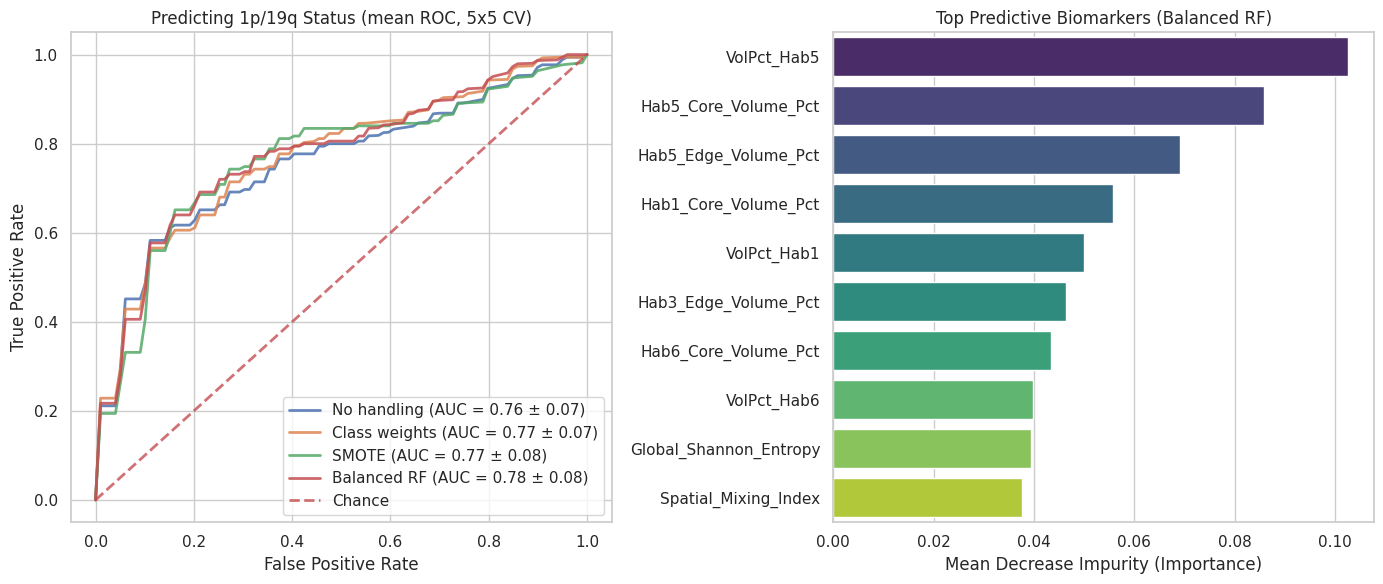

In [10]:
"""
Habitat-based 1p/19q classifier -- class-imbalance handling (100 negatives : 31 positives).
Fixed: Resolved Colab/Jupyter process deadlocks and unbuffered print output.
Updated: Now trains on all volume percentages and all spatial metrics across habitats 0 to 5.
"""
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, TunedThresholdClassifierCV

# --- Configuration ---
HABITAT_CSV = "/content/drive/MyDrive/Combined_Glioma_Outputs/patch_radiomics/habitats/patch_habitats.csv"
SPATIAL_CSV = "/content/drive/MyDrive/Combined_Glioma_Outputs/patch_radiomics/habitats/spatial_architectures.csv"

N_SPLITS, N_REPEATS = 5, 5       # 25 test folds in total
N_TREES = 300                    # more trees -> smoother probabilities -> steadier cut-off tuning
SEED = 42
PLOT_STRATEGY = "Balanced RF"    # setup shown in the feature-importance panel


def load_data():
    print("Loading data...", flush=True)
    # 1. Load and prepare volume fractions
    df_hab = pd.read_csv(HABITAT_CSV)
    df_known = df_hab[df_hab['label'].isin([0, 1])].copy()

    patient_counts = df_known.pivot_table(index=['standard_id', 'label'], columns='habitat', aggfunc='size', fill_value=0)
    patient_fractions = patient_counts.div(patient_counts.sum(axis=1), axis=0) * 100
    patient_fractions = patient_fractions.add_prefix('VolPct_Hab')
    patient_fractions = patient_fractions.reset_index()

    # 2. Load spatial metrics and merge
    df_spatial = pd.read_csv(SPATIAL_CSV)
    df_model = pd.merge(patient_fractions, df_spatial, on=['standard_id', 'label'], how='inner')

    # 3. Define Features (X) and Target (y)
    # Dynamically exclude non-feature metadata columns while ensuring ALL habitat-specific spatial columns remain
    exclude_cols = ['standard_id', 'label', 'Total_Patches']
    X = df_model.drop(columns=[c for c in exclude_cols if c in df_model.columns])
    y = df_model['label'].values.astype(int)
    return X.values, y, X.columns.tolist()


def build_strategies():
    """Four ways of handling the imbalance, all with identical forest settings.
    Note: n_jobs=1 prevents joblib deadlocks during nested CV in Colab/Jupyter."""
    rf = dict(n_estimators=N_TREES, max_depth=5, n_jobs=1, random_state=SEED)
    return {
        "No handling": RandomForestClassifier(**rf),
        # re-weights the classes inside every tree's bootstrap sample; no synthetic data
        "Class weights": RandomForestClassifier(class_weight="balanced_subsample", **rf),
        # SMOTE sits inside the pipeline, so it only ever sees the training part of a split
        "SMOTE": ImbPipeline([("smote", SMOTE(random_state=SEED)),
                              ("rf", RandomForestClassifier(**rf))]),
        # every tree sees all minority patients + an equal-sized random draw of majority patients
        "Balanced RF": BalancedRandomForestClassifier(
            sampling_strategy="all", replacement=True, bootstrap=False, **rf),
    }


def with_tuned_threshold(model):
    """Pick the probability cut-off by inner CV on the training split only (maximises
    balanced accuracy = mean of sensitivity and specificity), then refit on the full split."""
    return TunedThresholdClassifierCV(
        clone(model),
        scoring="balanced_accuracy",
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
        refit=True,
    )


def score_split(y_true, prob, pred):
    return {
        "ROC AUC": roc_auc_score(y_true, prob),
        "PR AUC": average_precision_score(y_true, prob),
        "Recall": recall_score(y_true, pred, zero_division=0),            # sensitivity
        "Spec": recall_score(y_true, pred, pos_label=0, zero_division=0),  # specificity
        "Prec": precision_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "BalAcc": balanced_accuracy_score(y_true, pred),
    }


def forest_importances(fitted):
    est = fitted.estimator_
    if hasattr(est, "named_steps"):          # SMOTE pipeline -> pull out the forest
        est = est.named_steps["rf"]
    return est.feature_importances_


def cross_validate_strategies(X, y):
    strategies = build_strategies()
    cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
    n_folds = cv.get_n_splits()
    mean_fpr = np.linspace(0, 1, 100)

    res = {name: {"@0.5": [], "@tuned": [], "tprs": [], "cutoffs": [], "imp": np.zeros(X.shape[1])}
           for name in strategies}

    for k, (train, test) in enumerate(cv.split(X, y), 1):
        for name, base in strategies.items():
            model = with_tuned_threshold(base).fit(X[train], y[train])
            prob = model.predict_proba(X[test])[:, 1]

            r = res[name]
            r["@0.5"].append(score_split(y[test], prob, (prob >= 0.5).astype(int)))
            r["@tuned"].append(score_split(y[test], prob, model.predict(X[test])))
            r["cutoffs"].append(model.best_threshold_)

            fpr, tpr, _ = roc_curve(y[test], prob)
            interp_tpr = np.interp(mean_fpr, fpr, tpr)
            interp_tpr[0] = 0.0
            r["tprs"].append(interp_tpr)
            r["imp"] += forest_importances(model) / n_folds

        # Explicit print with flush=True so notebook updates progress in real-time
        print(f"  Completed fold {k}/{n_folds}", flush=True)

    print("Cross-validation complete.\n", flush=True)
    return res, mean_fpr


def print_summary(res, y):
    table = {}
    for name, r in res.items():
        for cut in ("@0.5", "@tuned"):
            df = pd.DataFrame(r[cut])
            table[(name, cut)] = {c: f"{df[c].mean():.2f} ± {df[c].std():.2f}" for c in df}
    summary = pd.DataFrame(table).T
    summary.index.names = ["Strategy", "Cut-off"]

    prev = y.mean()
    print("\n" + "=" * 100)
    print(f" {N_REPEATS}x{N_SPLITS} repeated stratified CV -- mean ± SD over {N_SPLITS * N_REPEATS} test folds")
    print("=" * 100)
    print(summary.to_string())
    print("-" * 100)
    print(f" No-skill reference: ROC AUC 0.50 | PR AUC {prev:.2f} | BalAcc 0.50 | "
          f"accuracy of 'always negative' {1 - prev:.2f}")
    print(" Mean tuned cut-off: " + " | ".join(f"{n} {np.mean(r["cutoffs"]):.2f}" for n, r in res.items()))
    print("=" * 100 + "\n")


def plot_results(res, mean_fpr, feature_names):
    fig, ax = plt.subplots(1, 2, figsize=(14, 6))

    # Mean ROC curve of every strategy
    for name, r in res.items():
        aucs = [f["ROC AUC"] for f in r["@tuned"]]
        mean_tpr = np.mean(r["tprs"], axis=0)
        mean_tpr[-1] = 1.0
        ax[0].plot(mean_fpr, mean_tpr, lw=2, alpha=.85,
                   label=f"{name} (AUC = {np.mean(aucs):.2f} ± {np.std(aucs):.2f})")
    ax[0].plot([0, 1], [0, 1], linestyle='--', lw=2, color='r', label='Chance', alpha=.8)
    ax[0].set(xlim=[-0.05, 1.05], ylim=[-0.05, 1.05],
              title=f"Predicting 1p/19q Status (mean ROC, {N_REPEATS}x{N_SPLITS} CV)",
              xlabel='False Positive Rate', ylabel='True Positive Rate')
    ax[0].legend(loc="lower right")

    # Feature importances for the chosen strategy
    importances_df = pd.DataFrame({'Feature': feature_names, 'Importance': res[PLOT_STRATEGY]["imp"]})
    importances_df = importances_df.sort_values(by='Importance', ascending=False).head(10)
    sns.barplot(data=importances_df, x='Importance', y='Feature', hue='Feature',
                ax=ax[1], palette='viridis', legend=False)
    ax[1].set_title(f"Top Predictive Biomarkers ({PLOT_STRATEGY})")
    ax[1].set_xlabel("Mean Decrease Impurity (Importance)")
    ax[1].set_ylabel("")

    plt.tight_layout()
    plt.show()


def train_habitat_model():
    X, y, feature_names = load_data()
    print(f"Training model on {len(X)} patients with {X.shape[1]} features...", flush=True)
    print(f"Original Class Distribution: {np.bincount(y)}", flush=True)
    print(f"Running {N_REPEATS}x{N_SPLITS} repeated stratified CV for {len(build_strategies())} strategies "
          f"(threshold tuning is nested inside every training split)...\n", flush=True)

    res, mean_fpr = cross_validate_strategies(X, y)
    print_summary(res, y)
    plot_results(res, mean_fpr, feature_names)
    return res


if __name__ == "__main__":
    train_habitat_model()

In [11]:
# import os
# import shutil
# import pandas as pd
# from pathlib import Path

# # --- Configuration ---
# UCSF_IMAGES_DIR = "/content/drive/MyDrive/UCSF/images"
# UCSF_METADATA = "/content/drive/MyDrive/UCSF/labels.csv" # Update if different

# UTSW_IMAGES_DIR = "/content/drive/MyDrive/UTSW_processed"
# UTSW_METADATA = "/content/drive/MyDrive/UTSW_processed/updated_utsw_metadata.tsv"

# # The new unified drive root
# COMBINED_ROOT = "/content/drive/MyDrive/Combined_Glioma_Dataset"
# COMBINED_METADATA_PATH = os.path.join(COMBINED_ROOT, "combined_metadata.csv")

# def unify_datasets():
#     os.makedirs(COMBINED_ROOT, exist_ok=True)

#     # 1. Load UCSF Metadata
#     df_ucsf = pd.read_csv(UCSF_METADATA)
#     df_ucsf = df_ucsf[['patient_id', 'codeleted_1p19q']].rename(columns={'codeleted_1p19q': 'label'})
#     df_ucsf['source_dataset'] = 'UCSF'
#     df_ucsf['source_dir'] = UCSF_IMAGES_DIR

#     # 2. Load UTSW Metadata
#     df_utsw = pd.read_csv(UTSW_METADATA, sep='\t')
#     df_utsw = df_utsw[['patient_id', '1p19q']].rename(columns={'1p19q': 'label'})
#     df_utsw['source_dataset'] = 'UTSW'
#     df_utsw['source_dir'] = UTSW_IMAGES_DIR

#     # 3. Combine and create standard IDs
#     df_combined = pd.concat([df_ucsf, df_utsw], ignore_index=True)

#     # Create standard naming convention: GLIOMA_001, GLIOMA_002, etc.
#     df_combined['standard_id'] = [f"GLIOMA_{str(i).zfill(3)}" for i in range(1, len(df_combined) + 1)]

#     # Save the unified metadata
#     df_combined.to_csv(COMBINED_METADATA_PATH, index=False)
#     print(f"Unified metadata saved to {COMBINED_METADATA_PATH}")

#     # 4. Copy and Standardize Files
#     for _, row in df_combined.iterrows():
#         src_folder = os.path.join(row['source_dir'], row['patient_id'])
#         dst_folder = os.path.join(COMBINED_ROOT, row['standard_id'])

#         if not os.path.isdir(src_folder):
#             print(f"Warning: Source folder not found: {src_folder}")
#             continue

#         os.makedirs(dst_folder, exist_ok=True)

#         # Define how to map old filenames to standard filenames
#         # Both datasets use T1_GD.nii.gz for T1CE, but differ on segmentation naming
#         file_mapping = {
#             "T1.nii.gz": "T1.nii.gz",
#             "T1_GD.nii.gz": "T1CE.nii.gz",
#             "T2.nii.gz": "T2.nii.gz",
#             "FLAIR.nii.gz": "FLAIR.nii.gz"
#         }

#         # Add the specific segmentation mask for the dataset source
#         if row['source_dataset'] == 'UCSF':
#             file_mapping["seg_mask.nii.gz"] = "segmentation.nii.gz"
#         else:
#             file_mapping["segmentation.nii.gz"] = "segmentation.nii.gz"

#         # Copy files
#         for src_file, dst_file in file_mapping.items():
#             src_path = os.path.join(src_folder, src_file)
#             dst_path = os.path.join(dst_folder, dst_file)

#             if os.path.isfile(src_path):
#                 shutil.copy2(src_path, dst_path)
#             else:
#                 print(f"Missing file: {src_path}")

#     print(f"Dataset successfully unified and standardized at {COMBINED_ROOT}")

# if __name__ == "__main__":
#     unify_datasets()